# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

---

> **Criterio aplicado en la solución:** el conjunto de prueba permanece aislado hasta congelar las configuraciones. Las conclusiones se calculan a partir de los resultados del notebook.

In [1]:
# Importaciones y configuración reproducible
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_iris, load_diabetes
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    RandomForestRegressor, GradientBoostingRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    accuracy_score, f1_score, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=ConvergenceWarning)


# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

---

### Desarrollo

Cada fila representa una flor de iris. Las cuatro características son longitudes y anchos (en centímetros) de sépalos y pétalos. La etiqueta indica una de tres especies: *setosa*, *versicolor* o *virginica*.

In [2]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
iris_df = pd.DataFrame(X_iris, columns=iris.feature_names)
iris_df["clase"] = pd.Categorical.from_codes(y_iris, iris.target_names)

resumen_iris = pd.DataFrame({
    "Elemento": ["Instancias", "Características", "Forma de X", "Forma de y", "Clases"],
    "Valor": [len(X_iris), X_iris.shape[1], str(X_iris.shape), str(y_iris.shape), ", ".join(iris.target_names)],
})
display(resumen_iris)
display(Markdown("**Características:** " + "; ".join(iris.feature_names) + "."))
display(Markdown("**Cinco ejemplos:**"))
display(iris_df.head())

conteo_clases = iris_df["clase"].value_counts(sort=False).rename("cantidad").to_frame()
display(Markdown("**Cantidad de ejemplos por clase:**"))
display(conteo_clases)


,Elemento,Valor
0,Instancias,150
1,Características,4
2,Forma de X,"(150, 4)"
3,Forma de y,"(150,)"
4,Clases,"setosa, versicolor, virginica"


**Características:** sepal length (cm); sepal width (cm); petal length (cm); petal width (cm).

**Cinco ejemplos:**

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Cantidad de ejemplos por clase:**

,cantidad
clase,
setosa,50
versicolor,50
virginica,50


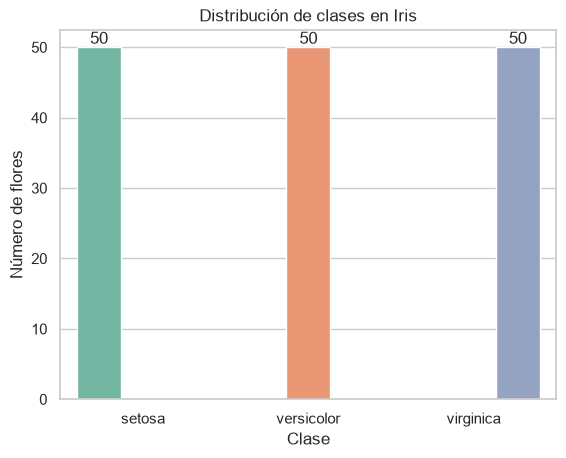

In [3]:
ax = sns.countplot(data=iris_df, x="clase", hue="clase", palette="Set2", legend=False)
ax.set(title="Distribución de clases en Iris", xlabel="Clase", ylabel="Número de flores")
for container in ax.containers:
    ax.bar_label(container)
plt.show()


## Protocolo común de clasificación

Se reserva 20 % para prueba y, del 80 % restante, 25 % para validación: 60 % entrenamiento, 20 % validación y 20 % prueba. La estratificación conserva el balance de clases. Los índices se guardan para poder inspeccionar casos concretos.


In [4]:
idx_iris = np.arange(len(X_iris))
Xc_temp, Xc_test, yc_temp, yc_test, idxc_temp, idxc_test = train_test_split(
    X_iris, y_iris, idx_iris, test_size=0.20, stratify=y_iris, random_state=SEED
)
Xc_train, Xc_val, yc_train, yc_val, idxc_train, idxc_val = train_test_split(
    Xc_temp, yc_temp, idxc_temp, test_size=0.25, stratify=yc_temp, random_state=SEED
)

particiones_iris = pd.DataFrame({
    "Partición": ["Entrenamiento", "Validación", "Prueba"],
    "n": [len(yc_train), len(yc_val), len(yc_test)],
    "Porcentaje": [len(yc_train), len(yc_val), len(yc_test)] / np.array([len(y_iris)] * 3) * 100,
})
display(particiones_iris)


,Partición,n,Porcentaje
0,Entrenamiento,90,60.0
1,Validación,30,20.0
2,Prueba,30,20.0


# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

---

# Desarrollo

## Respuestas a las predicciones iniciales (registradas antes de entrenar)

1. **Sensibilidad a escala.** Regresión logística, SVM lineal y MLP serán especialmente sensibles porque sus penalizaciones, productos internos y optimización dependen de la magnitud de las variables. GaussianNB también estima parámetros por variable. Los árboles y sus ensambles casi no cambian ante transformaciones monótonas de escala. Para cumplir un protocolo uniforme, aquí todos se encapsulan con `StandardScaler`.
2. **Frontera más simple.** La regresión logística y la SVM lineal producirán fronteras lineales; un árbol poco profundo también será simple, pero con cortes rectangulares por eje.
3. **Por qué no se conoce el ganador.** Depende de la muestra concreta, ruido, solapamiento de clases, sesgo/varianza e hiperparámetros. La flexibilidad no garantiza generalización.

## Selección limitada con validación

Se ensayan pocas configuraciones justificables. El criterio primario es F1 macro y el desempate es accuracy. La tabla siguiente es de **validación**, no de prueba.


In [5]:
def clf_pipe(model):
    return Pipeline([("escala", StandardScaler()), ("modelo", model)])

clasificadores = {
    "GaussianNB": [
        ("var_smoothing=1e-9", clf_pipe(GaussianNB(var_smoothing=1e-9))),
        ("var_smoothing=1e-7", clf_pipe(GaussianNB(var_smoothing=1e-7))),
    ],
    "Regresión logística": [
        ("C=0.1", clf_pipe(LogisticRegression(C=0.1, max_iter=3000, random_state=SEED))),
        ("C=1", clf_pipe(LogisticRegression(C=1, max_iter=3000, random_state=SEED))),
        ("C=10", clf_pipe(LogisticRegression(C=10, max_iter=3000, random_state=SEED))),
    ],
    "SVM lineal": [
        ("C=0.1", clf_pipe(LinearSVC(C=0.1, random_state=SEED, max_iter=10000))),
        ("C=1", clf_pipe(LinearSVC(C=1, random_state=SEED, max_iter=10000))),
        ("C=10", clf_pipe(LinearSVC(C=10, random_state=SEED, max_iter=10000))),
    ],
    "Árbol": [
        ("max_depth=2", clf_pipe(DecisionTreeClassifier(max_depth=2, random_state=SEED))),
        ("max_depth=3", clf_pipe(DecisionTreeClassifier(max_depth=3, random_state=SEED))),
        ("sin límite; min_leaf=2", clf_pipe(DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED))),
    ],
    "Random Forest": [
        ("300 árboles; depth=3", clf_pipe(RandomForestClassifier(n_estimators=300, max_depth=3, random_state=SEED, n_jobs=-1))),
        ("300 árboles; sin límite", clf_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))),
    ],
    "Gradient Boosting": [
        ("100; lr=0.05; depth=2", clf_pipe(GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=SEED))),
        ("100; lr=0.1; depth=2", clf_pipe(GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=SEED))),
        ("100; lr=0.05; depth=3", clf_pipe(GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=SEED))),
    ],
    "MLP": [
        ("hidden=(10,); alpha=0.001", clf_pipe(MLPClassifier(hidden_layer_sizes=(10,), alpha=0.001, max_iter=4000, random_state=SEED))),
        ("hidden=(20,10); alpha=0.001", clf_pipe(MLPClassifier(hidden_layer_sizes=(20, 10), alpha=0.001, max_iter=4000, random_state=SEED))),
        ("hidden=(20,10); alpha=0.01", clf_pipe(MLPClassifier(hidden_layer_sizes=(20, 10), alpha=0.01, max_iter=4000, random_state=SEED))),
    ],
}

filas_val_clf, mejores_clf = [], {}
for nombre, candidatos in clasificadores.items():
    resultados_modelo = []
    for configuracion, estimador in candidatos:
        ajustado = clone(estimador).fit(Xc_train, yc_train)
        pred = ajustado.predict(Xc_val)
        fila = {
            "Modelo": nombre,
            "Configuración": configuracion,
            "Accuracy validación": accuracy_score(yc_val, pred),
            "F1 macro validación": f1_score(yc_val, pred, average="macro"),
        }
        filas_val_clf.append(fila)
        resultados_modelo.append((fila["F1 macro validación"], fila["Accuracy validación"], configuracion, estimador))
    mejores_clf[nombre] = max(resultados_modelo, key=lambda x: (x[0], x[1], -candidatos.index((x[2], x[3]))))

validacion_clf = pd.DataFrame(filas_val_clf).sort_values(
    ["Modelo", "F1 macro validación", "Accuracy validación"], ascending=[True, False, False]
)
display(validacion_clf.round({"Accuracy validación": 3, "F1 macro validación": 3}))


,Modelo,Configuración,Accuracy validación,F1 macro validación
0,GaussianNB,var_smoothing=1e-9,0.933,0.933
1,GaussianNB,var_smoothing=1e-7,0.933,0.933
13,Gradient Boosting,100; lr=0.05; depth=2,0.933,0.933
14,Gradient Boosting,100; lr=0.1; depth=2,0.933,0.933
15,Gradient Boosting,100; lr=0.05; depth=3,0.900,0.900
16,MLP,"hidden=(10,); alpha=0.001",0.933,0.933
17,MLP,"hidden=(20,10); alpha=0.001",0.933,0.933
18,MLP,"hidden=(20,10); alpha=0.01",0.933,0.933
11,Random Forest,300 árboles; depth=3,0.933,0.933
12,Random Forest,300 árboles; sin límite,0.933,0.933


## Evaluación final en prueba

Tras congelar la mejor configuración de cada familia, se vuelve a ajustar con entrenamiento + validación. Este uso de validación ya es lícito porque las decisiones están cerradas. Todos los modelos se evalúan sobre exactamente las mismas 30 flores de prueba.


In [8]:
Xc_fit = np.vstack([Xc_train, Xc_val])
yc_fit = np.concatenate([yc_train, yc_val])
modelos_clf_finales, predicciones_clf, filas_test_clf = {}, {}, []

for nombre, (_, _, configuracion, estimador) in mejores_clf.items():
    final = clone(estimador).fit(Xc_fit, yc_fit)
    pred = final.predict(Xc_test)
    modelos_clf_finales[nombre] = final
    predicciones_clf[nombre] = pred
    filas_test_clf.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler (ajustado sin prueba)",
        "Hiperparámetros principales": configuracion,
        "Accuracy de prueba": accuracy_score(yc_test, pred),
        "F1 macro de prueba": f1_score(yc_test, pred, average="macro"),
    })

resultados_clf = pd.DataFrame(filas_test_clf).sort_values(
    ["F1 macro de prueba", "Accuracy de prueba"], ascending=False
).reset_index(drop=True)
display(resultados_clf.round({"Accuracy de prueba": 3, "F1 macro de prueba": 3}))


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,GaussianNB,StandardScaler (ajustado sin prueba),var_smoothing=1e-9,0.967,0.967
1,Random Forest,StandardScaler (ajustado sin prueba),300 árboles; depth=3,0.967,0.967
2,MLP,StandardScaler (ajustado sin prueba),"hidden=(10,); alpha=0.001",0.967,0.967
3,Regresión logística,StandardScaler (ajustado sin prueba),C=1,0.933,0.933
4,SVM lineal,StandardScaler (ajustado sin prueba),C=10,0.933,0.933
5,Árbol,StandardScaler (ajustado sin prueba),max_depth=2,0.933,0.933
6,Gradient Boosting,StandardScaler (ajustado sin prueba),100; lr=0.05; depth=2,0.933,0.933


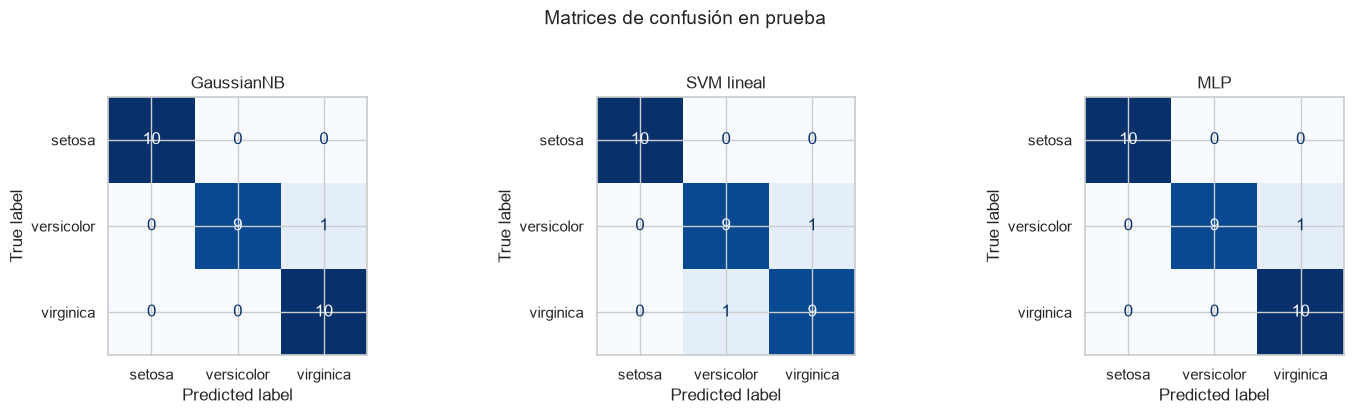

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, ["GaussianNB", "SVM lineal", "MLP"]):
    ConfusionMatrixDisplay.from_predictions(
        yc_test, predicciones_clf[nombre], display_labels=iris.target_names,
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
fig.suptitle("Matrices de confusión en prueba", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()


### Softmax y salida del MLP

En clasificación multiclase, `predict_proba` devuelve una distribución por fila: valores no negativos cuya suma es 1. La clase predicha corresponde al máximo (`argmax`). Pueden interpretarse como confianza relativa del modelo, pero no como certeza ni como probabilidades bien calibradas sin comprobar calibración.


In [10]:
proba_mlp = modelos_clf_finales["MLP"].predict_proba(Xc_test[:5])
salidas_mlp = pd.DataFrame(proba_mlp, columns=[f"P({c})" for c in iris.target_names])
salidas_mlp["suma"] = proba_mlp.sum(axis=1)
salidas_mlp["clase predicha"] = iris.target_names[np.argmax(proba_mlp, axis=1)]
salidas_mlp["clase real"] = iris.target_names[yc_test[:5]]
display(salidas_mlp.round(4))


,P(setosa),P(versicolor),P(virginica),suma,clase predicha,clase real
0,0.9972,0.0024,0.0004,1.0,setosa,setosa
1,0.0081,0.2509,0.7410,1.0,virginica,virginica
2,0.0493,0.9363,0.0144,1.0,versicolor,versicolor
3,0.0214,0.9708,0.0078,1.0,versicolor,versicolor
4,0.9988,0.0009,0.0003,1.0,setosa,setosa


In [11]:
# Dos errores observados (se recorren los modelos finales hasta reunir dos casos)
errores_clf = []
indices_ya_usados = set()
for nombre in resultados_clf["Modelo"]:
    pred = predicciones_clf[nombre]
    for pos in np.flatnonzero(pred != yc_test):
        if int(idxc_test[pos]) in indices_ya_usados:
            continue
        fila = {"Modelo": nombre, "índice original": int(idxc_test[pos]),
                "real": iris.target_names[yc_test[pos]], "predicha": iris.target_names[pred[pos]]}
        fila.update(dict(zip(iris.feature_names, Xc_test[pos])))
        errores_clf.append(fila)
        indices_ya_usados.add(int(idxc_test[pos]))
        if len(errores_clf) == 2:
            break
    if len(errores_clf) == 2:
        break

errores_clf_df = pd.DataFrame(errores_clf)
display(errores_clf_df)
if len(errores_clf_df) < 2:
    display(Markdown("Solo hubo menos de dos errores entre todas las predicciones finales; no se inventan casos."))


,Modelo,índice original,real,predicha,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,GaussianNB,77,versicolor,virginica,6.7,3.0,5.0,1.7
1,Regresión logística,134,virginica,versicolor,6.1,2.6,5.6,1.4


In [12]:
mejor_clf = resultados_clf.iloc[0]
mismo_orden = (
    resultados_clf.sort_values("Accuracy de prueba", ascending=False)["Modelo"].tolist()
    == resultados_clf.sort_values("F1 macro de prueba", ascending=False)["Modelo"].tolist()
)
display(Markdown(f"""### Interpretación de clasificación

1. **Mejor desempeño:** en esta partición, **{mejor_clf['Modelo']}** obtuvo el mayor criterio final, con accuracy **{mejor_clf['Accuracy de prueba']:.3f}** y F1 macro **{mejor_clf['F1 macro de prueba']:.3f}**. Esto describe esta prueba; no demuestra superioridad universal.
2. **Más sencillo de programar:** `GaussianNB`, porque requiere muy pocos hiperparámetros y una sola llamada `fit/predict` (el pipeline se usa para mantener el protocolo común).
3. **Accuracy frente a F1 macro:** {'sí producen el mismo orden aquí' if mismo_orden else 'no producen exactamente el mismo orden aquí'}. Como Iris está balanceado, suelen ser cercanas; aun así, accuracy suma aciertos globales y F1 macro da el mismo peso al F1 de cada clase.
4. **Macro frente a micro:** macro calcula la métrica por clase y promedia sin ponderar; micro agrega TP/FP/FN de todas las clases antes de calcularla. En clasificación monoclase multiclase, F1 micro coincide con accuracy.
5. **Aporte del MLP:** sus capas ocultas y activaciones pueden aprender fronteras no lineales e interacciones. Ese poder añade coste de ajuste, sensibilidad a hiperparámetros y riesgo de sobreajuste; en un dataset pequeño no garantiza mejorar a un modelo lineal.

**Sobre los dos errores:** las filas mostradas permiten observar valores compatibles con solapamiento entre especies, especialmente en medidas de pétalo. Podemos afirmar qué variables tenía cada flor y qué confundió el modelo, pero **no** atribuir causalmente el error a una variable ni saber si hay ruido de etiqueta, una medición atípica o una muestra poco representativa sin evidencia adicional.
"""))


### Interpretación de clasificación

1. **Mejor desempeño:** en esta partición, **GaussianNB** obtuvo el mayor criterio final, con accuracy **0.967** y F1 macro **0.967**. Esto describe esta prueba; no demuestra superioridad universal.
2. **Más sencillo de programar:** `GaussianNB`, porque requiere muy pocos hiperparámetros y una sola llamada `fit/predict` (el pipeline se usa para mantener el protocolo común).
3. **Accuracy frente a F1 macro:** sí producen el mismo orden aquí. Como Iris está balanceado, suelen ser cercanas; aun así, accuracy suma aciertos globales y F1 macro da el mismo peso al F1 de cada clase.
4. **Macro frente a micro:** macro calcula la métrica por clase y promedia sin ponderar; micro agrega TP/FP/FN de todas las clases antes de calcularla. En clasificación monoclase multiclase, F1 micro coincide con accuracy.
5. **Aporte del MLP:** sus capas ocultas y activaciones pueden aprender fronteras no lineales e interacciones. Ese poder añade coste de ajuste, sensibilidad a hiperparámetros y riesgo de sobreajuste; en un dataset pequeño no garantiza mejorar a un modelo lineal.

**Sobre los dos errores:** las filas mostradas permiten observar valores compatibles con solapamiento entre especies, especialmente en medidas de pétalo. Podemos afirmar qué variables tenía cada flor y qué confundió el modelo, pero **no** atribuir causalmente el error a una variable ni saber si hay ruido de etiqueta, una medición atípica o una muestra poco representativa sin evidencia adicional.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

---

# Desarrollo

## Desarrollo: dataset Diabetes y predicción inicial

Cada instancia corresponde a una persona con diabetes. El objetivo es una medida cuantitativa de progresión de la enfermedad **un año después** de la línea base. Las diez variables son edad, sexo, índice de masa corporal, presión arterial media y seis mediciones séricas (`s1`–`s6`).

Según la descripción de scikit-learn, las características suministradas por defecto ya están centradas y escaladas: cada columna se centra y se divide por su desviación estándar multiplicada por la raíz del número de muestras. Por eso sus números **no deben interpretarse como las unidades clínicas originales**.

**Predicción previa:** no espero que el modelo más flexible siempre tenga menor error nuevo. Puede reducir el error de entrenamiento y a la vez aprender ruido (alta varianza); el resultado depende de regularización, tamaño muestral y relación señal/ruido.


In [13]:
diabetes = load_diabetes()
Xd, yd = diabetes.data, diabetes.target
diabetes_df = pd.DataFrame(Xd, columns=diabetes.feature_names)
diabetes_df["progresión"] = yd

resumen_diabetes = pd.DataFrame({
    "Elemento": ["Instancias", "Características", "Forma de X", "Forma de y", "Rango del objetivo"],
    "Valor": [len(Xd), Xd.shape[1], str(Xd.shape), str(yd.shape), f"{yd.min():.0f}–{yd.max():.0f}"],
})
display(resumen_diabetes)
display(Markdown("**Variables:** " + ", ".join(diabetes.feature_names) + "."))
display(diabetes_df.head())


,Elemento,Valor
0,Instancias,442
1,Características,10
2,Forma de X,"(442, 10)"
3,Forma de y,"(442,)"
4,Rango del objetivo,25–346


**Variables:** age, sex, bmi, bp, s1, s2, s3, s4, s5, s6.

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progresión
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0


In [14]:
idx_d = np.arange(len(Xd))
Xd_temp, Xd_test, yd_temp, yd_test, idxd_temp, idxd_test = train_test_split(
    Xd, yd, idx_d, test_size=0.20, random_state=SEED
)
Xd_train, Xd_val, yd_train, yd_val, idxd_train, idxd_val = train_test_split(
    Xd_temp, yd_temp, idxd_temp, test_size=0.25, random_state=SEED
)
display(pd.DataFrame({
    "Partición": ["Entrenamiento", "Validación", "Prueba"],
    "n": [len(yd_train), len(yd_val), len(yd_test)],
    "Porcentaje": np.array([len(yd_train), len(yd_val), len(yd_test)]) / len(yd) * 100,
}))


,Partición,n,Porcentaje
0,Entrenamiento,264,59.7285
1,Validación,89,20.1357
2,Prueba,89,20.1357


## Selección de regresores con validación

Se minimiza RMSE de validación, con MAE como desempate. El escalamiento está dentro de los pipelines cuando corresponde. Para el MLP, `TransformedTargetRegressor` estandariza el objetivo usando solo los datos entregados a `fit` y revierte automáticamente las predicciones a la escala original.


In [15]:
def reg_pipe(model, escalar=True):
    pasos = [("escala", StandardScaler())] if escalar else []
    return Pipeline(pasos + [("modelo", model)])

def mlp_reg(hidden, alpha):
    base = reg_pipe(MLPRegressor(
        hidden_layer_sizes=hidden, alpha=alpha, solver="lbfgs",
        max_iter=3000, random_state=SEED
    ))
    return TransformedTargetRegressor(regressor=base, transformer=StandardScaler())

regresores = {
    "Regresión lineal": [("sin penalización", reg_pipe(LinearRegression()))],
    "Ridge": [(f"alpha={a:g}", reg_pipe(Ridge(alpha=a))) for a in [0.01, 0.1, 1, 10, 100]],
    "Lasso": [(f"alpha={a:g}", reg_pipe(Lasso(alpha=a, max_iter=20000))) for a in [0.01, 0.1, 1, 5, 10]],
    "kNN": [(f"k={k}", reg_pipe(KNeighborsRegressor(n_neighbors=k, weights="distance"))) for k in [5, 10, 20]],
    "Árbol": [(f"depth={d}", reg_pipe(DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=SEED), False)) for d in [2, 3, 5, None]],
    "Random Forest": [
        ("300; depth=3; leaf=3", reg_pipe(RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=3, random_state=SEED, n_jobs=-1), False)),
        ("300; sin límite; leaf=3", reg_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1), False)),
        ("300; sin límite; leaf=5", reg_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1), False)),
    ],
    "Gradient Boosting": [
        ("200; lr=0.03; depth=1", reg_pipe(GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=1, random_state=SEED), False)),
        ("200; lr=0.03; depth=2", reg_pipe(GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=2, random_state=SEED), False)),
        ("100; lr=0.05; depth=2", reg_pipe(GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=SEED), False)),
    ],
    "MLP": [
        ("hidden=(16,); alpha=0.001", mlp_reg((16,), 0.001)),
        ("hidden=(32,); alpha=0.01", mlp_reg((32,), 0.01)),
        ("hidden=(32,16); alpha=0.01", mlp_reg((32, 16), 0.01)),
        ("hidden=(16,); alpha=10", mlp_reg((16,), 10)),
    ],
}

filas_val_reg, mejores_reg = [], {}
for nombre, candidatos in regresores.items():
    resultados_modelo = []
    for orden, (configuracion, estimador) in enumerate(candidatos):
        ajustado = clone(estimador).fit(Xd_train, yd_train)
        pred_train, pred_val = ajustado.predict(Xd_train), ajustado.predict(Xd_val)
        fila = {
            "Modelo": nombre, "Configuración": configuracion,
            "RMSE entrenamiento": mean_squared_error(yd_train, pred_train) ** 0.5,
            "RMSE validación": mean_squared_error(yd_val, pred_val) ** 0.5,
            "MAE validación": mean_absolute_error(yd_val, pred_val),
        }
        filas_val_reg.append(fila)
        resultados_modelo.append((fila["RMSE validación"], fila["MAE validación"], orden, configuracion, estimador))
    mejores_reg[nombre] = min(resultados_modelo, key=lambda x: (x[0], x[1], x[2]))

validacion_reg = pd.DataFrame(filas_val_reg).sort_values(["Modelo", "RMSE validación"])
display(validacion_reg.round({"RMSE entrenamiento": 2, "RMSE validación": 2, "MAE validación": 2}))


,Modelo,Configuración,RMSE entrenamiento,RMSE validación,MAE validación
22,Gradient Boosting,200; lr=0.03; depth=2,43.13,53.03,43.14
23,Gradient Boosting,100; lr=0.05; depth=2,44.64,53.19,43.19
21,Gradient Boosting,200; lr=0.03; depth=1,51.90,53.92,44.48
8,Lasso,alpha=1,54.91,51.06,42.47
7,Lasso,alpha=0.1,54.65,51.10,42.64
6,Lasso,alpha=0.01,54.61,51.18,42.91
9,Lasso,alpha=5,56.47,51.37,43.29
10,Lasso,alpha=10,58.43,53.15,45.14
27,MLP,"hidden=(16,); alpha=10",51.50,51.75,42.88
26,MLP,"hidden=(32,16); alpha=0.01",0.24,77.27,59.80


## Regularización: Ridge y Lasso

Este análisis usa exclusivamente entrenamiento y validación. Los coeficientes corresponden a variables estandarizadas, por lo que sus magnitudes son comparables dentro de este experimento. Se informan normas L1/L2, máximo absoluto, coeficientes exactamente nulos (tolerancia numérica `1e-8`) y RMSE.


,Modelo,alpha,Norma L1,Norma L2,Máx. |coef|,Coef. nulos,RMSE entrenamiento,RMSE validación
0,Ridge,0.001,198.22,78.09,51.08,0,54.61,51.19
1,Ridge,0.010,197.67,77.85,50.87,0,54.61,51.19
2,Ridge,0.100,192.45,75.55,48.92,0,54.61,51.17
3,Ridge,1.000,156.99,60.88,35.69,0,54.64,51.10
4,Ridge,10.000,108.88,41.92,25.06,0,54.84,51.16
5,Ridge,100.000,87.80,32.78,20.16,0,55.86,51.74
6,Lasso,0.001,197.80,77.91,50.93,0,54.61,51.19
7,Lasso,0.010,193.49,76.05,49.35,0,54.61,51.18
8,Lasso,0.100,150.43,58.77,33.57,0,54.65,51.10
9,Lasso,1.000,100.61,41.99,25.66,1,54.91,51.06


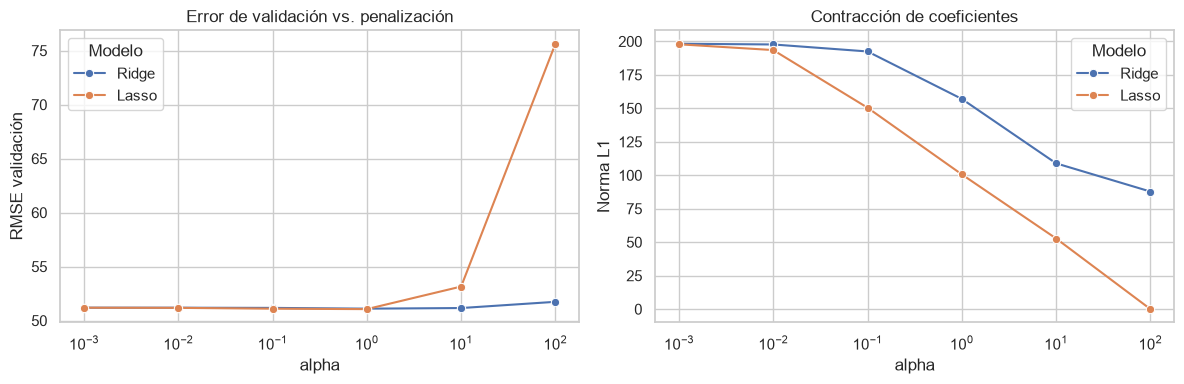

In [16]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
filas_regularizacion = []
for familia, clase in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for alpha in alphas:
        modelo = reg_pipe(clase(alpha=alpha, max_iter=30000) if familia == "Lasso" else clase(alpha=alpha))
        modelo.fit(Xd_train, yd_train)
        coef = modelo.named_steps["modelo"].coef_
        filas_regularizacion.append({
            "Modelo": familia, "alpha": alpha,
            "Norma L1": np.abs(coef).sum(), "Norma L2": np.linalg.norm(coef),
            "Máx. |coef|": np.abs(coef).max(), "Coef. nulos": int(np.sum(np.abs(coef) < 1e-8)),
            "RMSE entrenamiento": mean_squared_error(yd_train, modelo.predict(Xd_train)) ** 0.5,
            "RMSE validación": mean_squared_error(yd_val, modelo.predict(Xd_val)) ** 0.5,
        })

regularizacion = pd.DataFrame(filas_regularizacion)
display(regularizacion.round({
    "alpha": 3, "Norma L1": 2, "Norma L2": 2, "Máx. |coef|": 2,
    "RMSE entrenamiento": 2, "RMSE validación": 2,
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=regularizacion, x="alpha", y="RMSE validación", hue="Modelo", marker="o", ax=axes[0])
sns.lineplot(data=regularizacion, x="alpha", y="Norma L1", hue="Modelo", marker="o", ax=axes[1])
for ax in axes:
    ax.set_xscale("log")
axes[0].set_title("Error de validación vs. penalización")
axes[1].set_title("Contracción de coeficientes")
plt.tight_layout()
plt.show()


## Evaluación final de regresión

Se congelan las configuraciones escogidas arriba, se reajustan con entrenamiento + validación y se evalúan una sola vez en prueba.


In [17]:
Xd_fit = np.vstack([Xd_train, Xd_val])
yd_fit = np.concatenate([yd_train, yd_val])
modelos_reg_finales, predicciones_reg, filas_test_reg = {}, {}, []

for nombre, (_, _, _, configuracion, estimador) in mejores_reg.items():
    final = clone(estimador).fit(Xd_fit, yd_fit)
    pred = final.predict(Xd_test)
    modelos_reg_finales[nombre] = final
    predicciones_reg[nombre] = pred
    filas_test_reg.append({
        "Modelo": nombre, "Configuración congelada": configuracion,
        "MAE": mean_absolute_error(yd_test, pred),
        "RMSE": mean_squared_error(yd_test, pred) ** 0.5,
        "R²": r2_score(yd_test, pred),
    })

resultados_reg = pd.DataFrame(filas_test_reg).sort_values("RMSE").reset_index(drop=True)
display(resultados_reg.round({"MAE": 2, "RMSE": 2, "R²": 3}))


,Modelo,Configuración congelada,MAE,RMSE,R²
0,MLP,"hidden=(16,); alpha=10",40.93,51.56,0.498
1,Gradient Boosting,200; lr=0.03; depth=2,42.51,52.38,0.482
2,Random Forest,300; sin límite; leaf=5,42.77,53.00,0.470
3,Lasso,alpha=1,42.80,53.15,0.467
4,Ridge,alpha=1,42.81,53.78,0.454
5,Regresión lineal,sin penalización,42.79,53.85,0.453
6,kNN,k=20,44.82,54.67,0.436
7,Árbol,depth=3,45.18,55.63,0.416


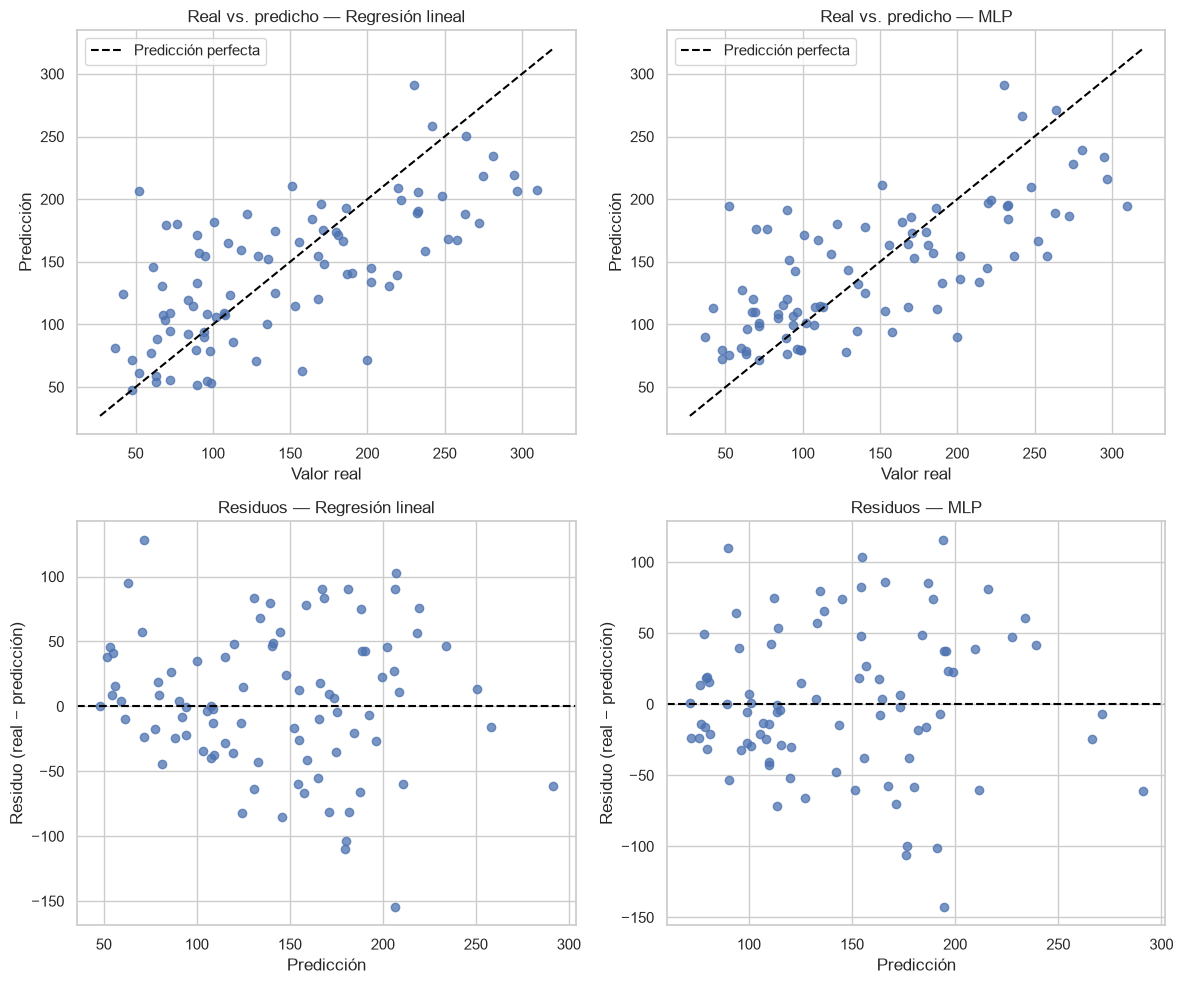

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
limites = [yd_test.min() - 10, yd_test.max() + 10]
for columna, nombre in enumerate(["Regresión lineal", "MLP"]):
    pred = predicciones_reg[nombre]
    axes[0, columna].scatter(yd_test, pred, alpha=0.75)
    axes[0, columna].plot(limites, limites, "--", color="black", label="Predicción perfecta")
    axes[0, columna].set(xlabel="Valor real", ylabel="Predicción", title=f"Real vs. predicho — {nombre}")
    axes[0, columna].legend()
    residuos = yd_test - pred
    axes[1, columna].scatter(pred, residuos, alpha=0.75)
    axes[1, columna].axhline(0, linestyle="--", color="black")
    axes[1, columna].set(xlabel="Predicción", ylabel="Residuo (real − predicción)", title=f"Residuos — {nombre}")
plt.tight_layout()
plt.show()


In [18]:
# Dos mayores errores absolutos para cada modelo solicitado
errores_grandes = []
for nombre in ["Regresión lineal", "MLP"]:
    pred = predicciones_reg[nombre]
    error_abs = np.abs(yd_test - pred)
    for pos in np.argsort(error_abs)[-2:][::-1]:
        fila = {
            "Modelo": nombre, "índice original": int(idxd_test[pos]),
            "real": yd_test[pos], "predicción": pred[pos], "error absoluto": error_abs[pos],
        }
        fila.update(dict(zip(diabetes.feature_names, Xd_test[pos])))
        errores_grandes.append(fila)
display(pd.DataFrame(errores_grandes).round({"real": 1, "predicción": 1, "error absoluto": 1}))


,Modelo,índice original,real,predicción,error absoluto,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,Regresión lineal,56,52.0,206.5,154.5,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
1,Regresión lineal,77,200.0,71.7,128.3,-0.0963,-0.0446,-0.0364,-0.0745,-0.0387,-0.0276,0.0155,-0.0395,-0.0741,-0.0011
2,MLP,56,52.0,194.6,142.6,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
3,MLP,9,310.0,194.3,115.7,-0.0709,-0.0446,0.0391,-0.0332,-0.0126,-0.0345,-0.0250,-0.0026,0.0677,-0.0135


In [19]:
mejor_rmse = resultados_reg.loc[resultados_reg["RMSE"].idxmin()]
mejor_mae = resultados_reg.loc[resultados_reg["MAE"].idxmin()]
ridge_extremos = regularizacion[regularizacion["Modelo"] == "Ridge"].sort_values("alpha")
lasso_extremos = regularizacion[regularizacion["Modelo"] == "Lasso"].sort_values("alpha")

display(Markdown(f"""### Interpretación de regresión

1. **Mejor desempeño:** por RMSE, **{mejor_rmse['Modelo']}** fue el mejor en esta prueba (RMSE = **{mejor_rmse['RMSE']:.2f}**, MAE = **{mejor_rmse['MAE']:.2f}**, R² = **{mejor_rmse['R²']:.3f}**). Por MAE, el ganador fue **{mejor_mae['Modelo']}**. La prueba describe generalización en esta partición, no una ley universal.
2. **MAE y RMSE:** MAE pondera linealmente todos los errores; RMSE eleva al cuadrado y castiga mucho más los errores grandes. Por ello pueden elegir modelos distintos.
3. **R² negativo:** significa que, en esos datos, el modelo es peor que predecir siempre la media del objetivo del conjunto evaluado.
4. **Regularización:** al aumentar `alpha` se observa contracción de coeficientes. Ridge normalmente los acerca a cero de forma gradual; Lasso puede llevar varios exactamente a cero (selección de variables). Una penalización moderada puede reducir varianza; una excesiva aumenta sesgo y suele elevar tanto el error de entrenamiento como el de validación. Los valores concretos están en la tabla y el gráfico.
5. **Errores grandes:** pueden surgir por ruido, variables relevantes ausentes, casos poco representados, no linealidades o límites propios del modelo. Las filas inspeccionadas muestran asociación, pero no identifican por sí solas la causa.
6. **Causalidad:** un coeficiente predictivo no demuestra una relación causal. Puede reflejar confusión, selección de muestra, correlación entre variables o causalidad inversa; se necesitaría un diseño causal y supuestos adicionales.

### Conclusión

La separación entre selección y prueba evita optimismo indebido. Los resultados ilustran que mayor flexibilidad no implica automáticamente mejor generalización y que la métrica elegida cambia qué aspecto del error se prioriza.
"""))


### Interpretación de regresión

1. **Mejor desempeño:** por RMSE, **MLP** fue el mejor en esta prueba (RMSE = **51.56**, MAE = **40.93**, R² = **0.498**). Por MAE, el ganador fue **MLP**. La prueba describe generalización en esta partición, no una ley universal.
2. **MAE y RMSE:** MAE pondera linealmente todos los errores; RMSE eleva al cuadrado y castiga mucho más los errores grandes. Por ello pueden elegir modelos distintos.
3. **R² negativo:** significa que, en esos datos, el modelo es peor que predecir siempre la media del objetivo del conjunto evaluado.
4. **Regularización:** al aumentar `alpha` se observa contracción de coeficientes. Ridge normalmente los acerca a cero de forma gradual; Lasso puede llevar varios exactamente a cero (selección de variables). Una penalización moderada puede reducir varianza; una excesiva aumenta sesgo y suele elevar tanto el error de entrenamiento como el de validación. Los valores concretos están en la tabla y el gráfico.
5. **Errores grandes:** pueden surgir por ruido, variables relevantes ausentes, casos poco representados, no linealidades o límites propios del modelo. Las filas inspeccionadas muestran asociación, pero no identifican por sí solas la causa.
6. **Causalidad:** un coeficiente predictivo no demuestra una relación causal. Puede reflejar confusión, selección de muestra, correlación entre variables o causalidad inversa; se necesitaría un diseño causal y supuestos adicionales.

### Conclusión

La separación entre selección y prueba evita optimismo indebido. Los resultados ilustran que mayor flexibilidad no implica automáticamente mejor generalización y que la métrica elegida cambia qué aspecto del error se prioriza.
